<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%9B%D0%A05_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Виконав:** студент групи ФІТ 3-12 Мехед Єгор

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_files = glob.glob(os.path.join(path, "*.csv"))
file_path = csv_files[0] if csv_files else os.path.join(path, "kaggel_weather_2013_to_2024.csv")

df = pd.read_csv(file_path)
display(df.head())
display(df.describe())


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
date_col = 'DATE' if 'DATE' in df.columns else [c for c in df.columns if 'date' in c.lower()][0]
df[date_col] = pd.to_datetime(df[date_col], format='mixed', dayfirst=False)
df = df.sort_values(by=date_col).reset_index(drop=True)

unnamed_cols = [c for c in df.columns if 'unnamed' in c.lower()]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)

df = df.set_index(date_col)
df.index.name = 'DATE'

target_col = 'temp' if 'temp' in df.columns else df.select_dtypes(include=[np.number]).columns[0]
display(df.head())


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [6]:
# Перевірте наявність пропущених значень
print("Кількість пропущених значень у колонках:")
print(df.isnull().sum())

if df[target_col].isnull().sum() > 0:
    df[target_col] = df[target_col].interpolate(method='time').bfill().ffill()


Кількість пропущених значень у колонках:
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64


Графік температури

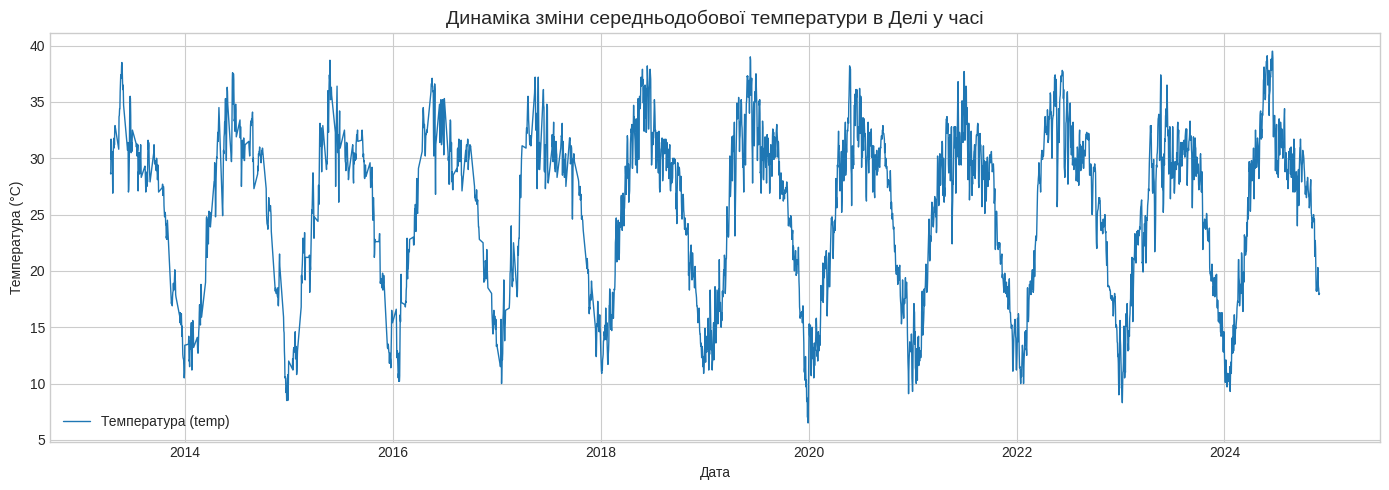

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], color='tab:blue', linewidth=1, label='Температура (temp)')
plt.title('Динаміка зміни середньодобової температури в Делі у часі', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


Ковзне середнє

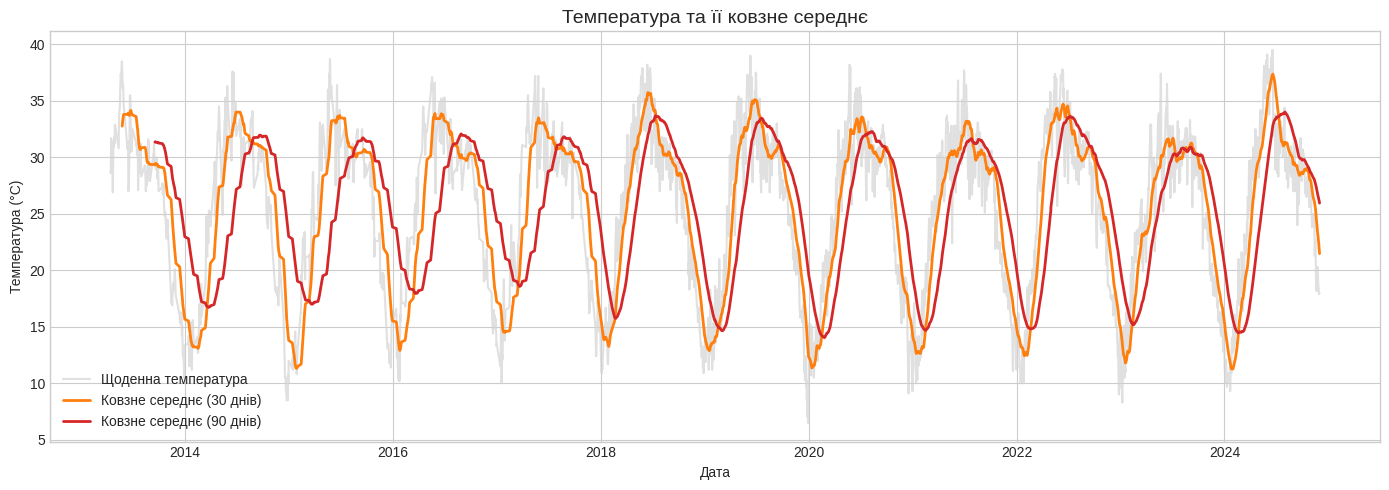

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['Rolling_Mean_30'] = df[target_col].rolling(window=30).mean()
df['Rolling_Mean_90'] = df[target_col].rolling(window=90).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], color='lightgray', alpha=0.7, label='Щоденна температура')
plt.plot(df.index, df['Rolling_Mean_30'], color='tab:orange', linewidth=2, label='Ковзне середнє (30 днів)')
plt.plot(df.index, df['Rolling_Mean_90'], color='tab:red', linewidth=2, label='Ковзне середнє (90 днів)')
plt.title('Температура та її ковзне середнє', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


Розподіл температури

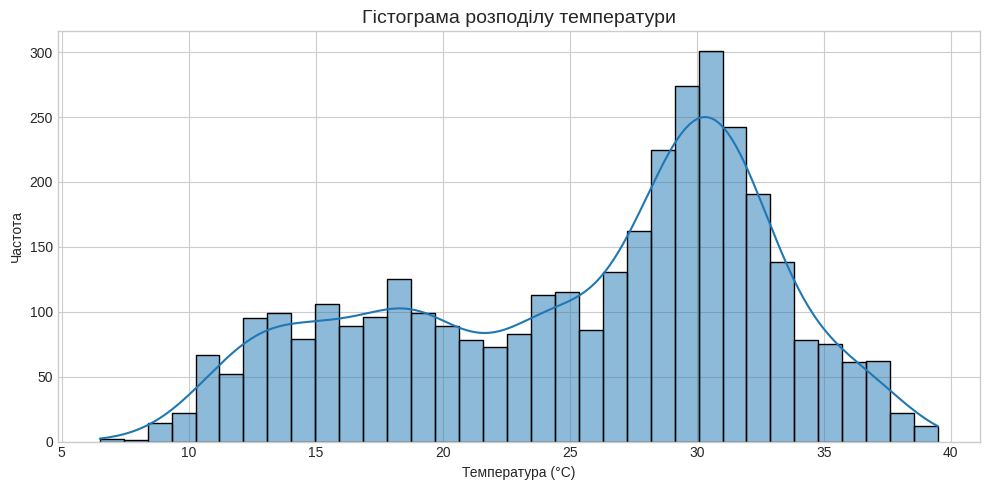

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
sns.histplot(df[target_col], bins=35, kde=True, color='tab:blue')
plt.title('Гістограма розподілу температури', fontsize=14)
plt.xlabel('Температура (°C)')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()


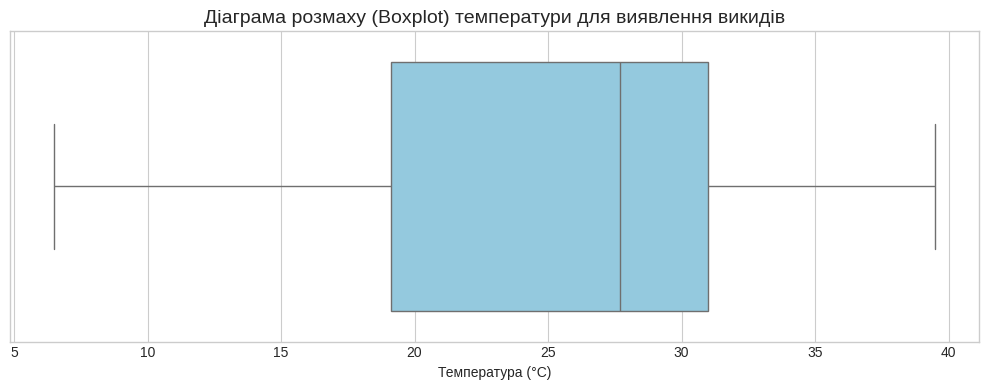

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[target_col], color='skyblue')
plt.title('Діаграма розмаху (Boxplot) температури для виявлення викидів', fontsize=14)
plt.xlabel('Температура (°C)')
plt.tight_layout()
plt.show()


Аналіз автокореляції
ACF

PACF

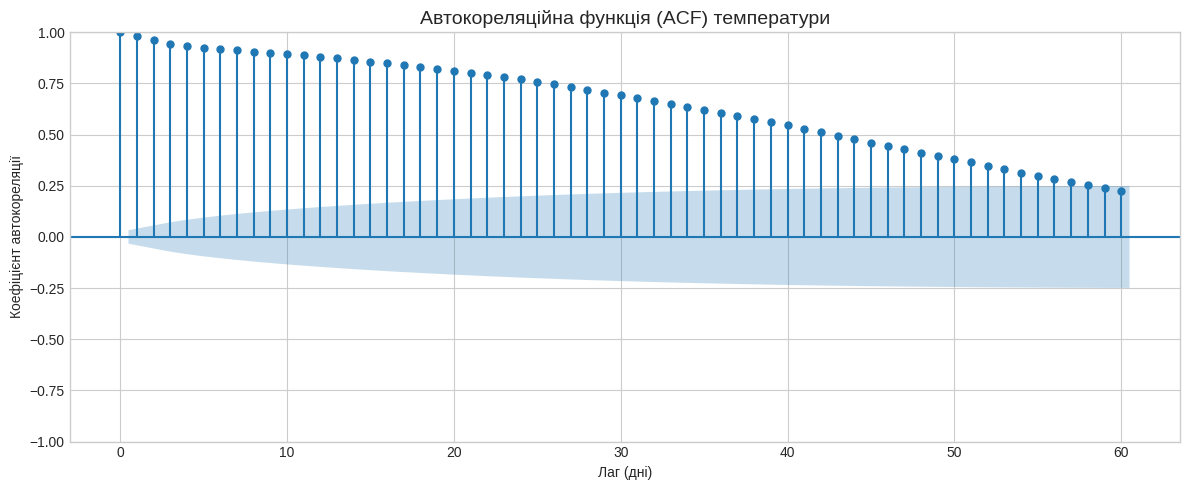

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df[target_col].dropna(), lags=60, ax=ax)
ax.set_title('Автокореляційна функція (ACF) температури', fontsize=14)
ax.set_xlabel('Лаг (дні)')
ax.set_ylabel('Коефіцієнт автокореляції')
plt.tight_layout()
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

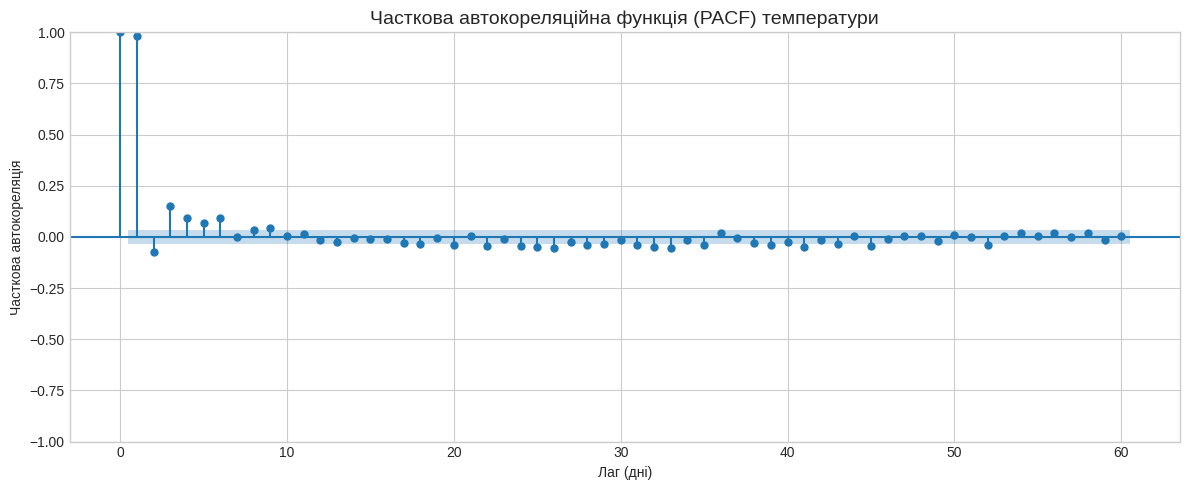

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(df[target_col].dropna(), lags=60, method='ywm', ax=ax)
ax.set_title('Часткова автокореляційна функція (PACF) температури', fontsize=14)
ax.set_xlabel('Лаг (дні)')
ax.set_ylabel('Часткова автокореляція')
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
ts = df[target_col].dropna()
train_size = int(len(ts) * 0.8)
train, test = ts.iloc[:train_size], ts.iloc[train_size:]

print(f"Загальний розмір ряду: {len(ts)}")
print(f"Тренувальна вибірка (80%): {len(train)} записів ({train.index.min().date()} — {train.index.max().date()})")
print(f"Тестова вибірка (20%): {len(test)} записів ({test.index.min().date()} — {test.index.max().date()})")


Загальний розмір ряду: 3557
Тренувальна вибірка (80%): 2845 записів (2013-04-14 — 2022-12-19)
Тестова вибірка (20%): 712 записів (2022-12-20 — 2024-11-30)


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train.values, order=(5, 1, 2))
arima_result = arima_model.fit()

arima_forecast_values = arima_result.forecast(steps=len(test))
arima_forecast = pd.Series(arima_forecast_values, index=test.index)


In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.summary())


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Fri, 06 Nov 2026   AIC                           9954.101
Time:                        02:23:57   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

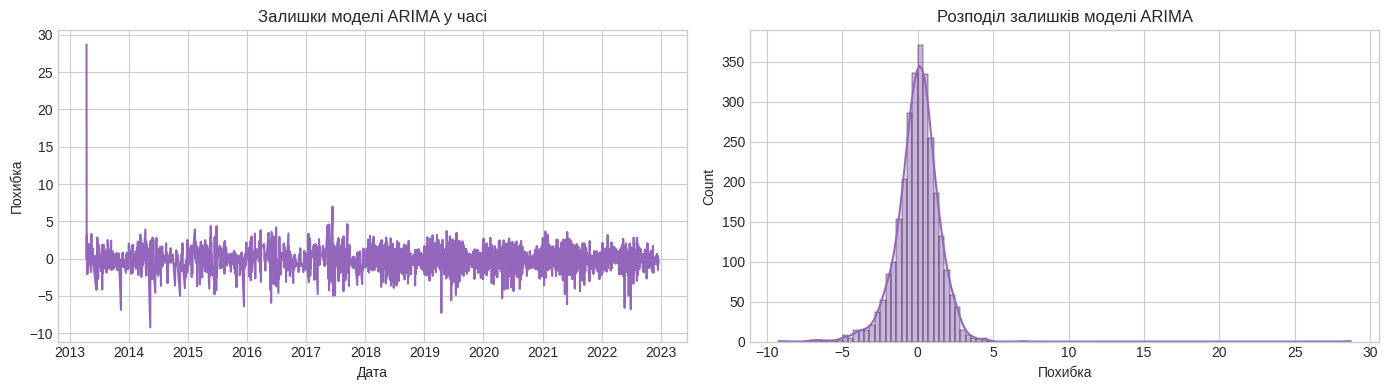

In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = pd.Series(arima_result.resid, index=train.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals, color='tab:purple')
axes[0].set_title('Залишки моделі ARIMA у часі')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Похибка')

sns.histplot(residuals, kde=True, ax=axes[1], color='tab:purple')
axes[1].set_title('Розподіл залишків моделі ARIMA')
axes[1].set_xlabel('Похибка')

plt.tight_layout()
plt.show()


In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = calculate_mape(test, arima_forecast)

print(f"ARIMA MAE:  {arima_mae:.4f}")
print(f"ARIMA RMSE: {arima_rmse:.4f}")
print(f"ARIMA MAPE: {arima_mape:.2f}%")


ARIMA MAE:  10.9278
ARIMA RMSE: 12.5009
ARIMA MAPE: 39.59%


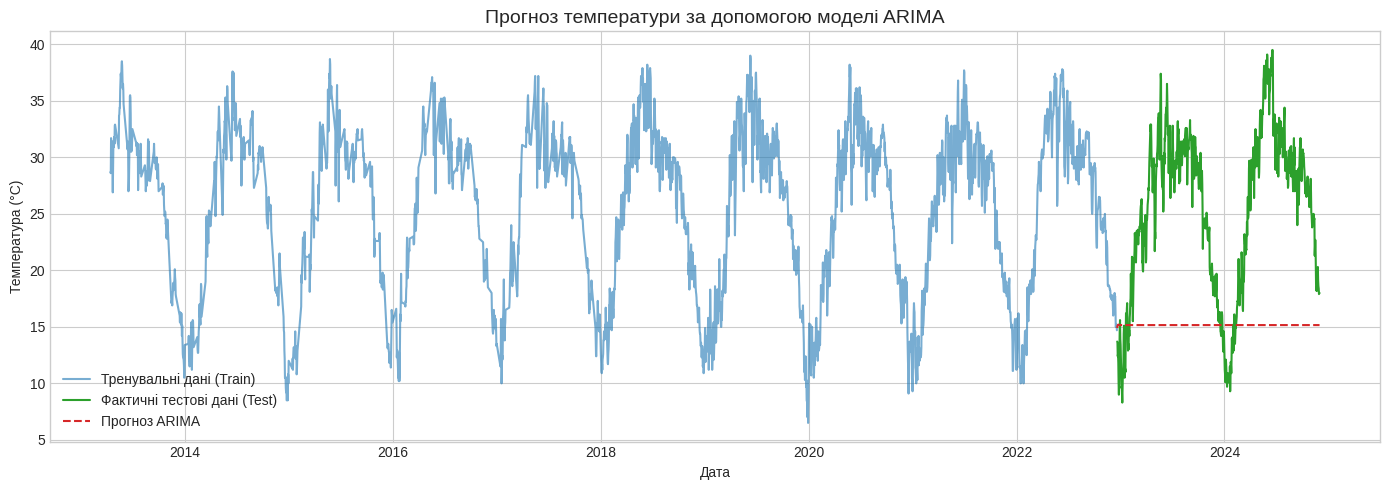

In [18]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Тренувальні дані (Train)', color='tab:blue', alpha=0.6)
plt.plot(test.index, test, label='Фактичні тестові дані (Test)', color='tab:green')
plt.plot(test.index, arima_forecast, label='Прогноз ARIMA', color='tab:red', linestyle='--')
plt.title('Прогноз температури за допомогою моделі ARIMA', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = train.reset_index()
prophet_train.columns = ['ds', 'y']

prophet_test = test.reset_index()
prophet_test.columns = ['ds', 'y']

display(prophet_train.head())


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
prophet_model.fit(prophet_train)


Прогноз

In [21]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_test[['ds']].copy()
prophet_forecast_df = prophet_model.predict(future)
prophet_forecast = pd.Series(prophet_forecast_df['yhat'].values, index=test.index)
display(prophet_forecast_df[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,13.892037,11.400401,16.577748
1,2022-12-21,13.738187,11.107511,16.518406
2,2022-12-22,13.534303,10.990966,16.242843
3,2022-12-23,13.344060,10.686440,15.938649
4,2022-12-24,13.189955,10.639291,16.132125


In [22]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(test, prophet_forecast)
prophet_rmse = np.sqrt(mean_squared_error(test, prophet_forecast))
prophet_mape = calculate_mape(test, prophet_forecast)

print(f"Prophet MAE:  {prophet_mae:.4f}")
print(f"Prophet RMSE: {prophet_rmse:.4f}")
print(f"Prophet MAPE: {prophet_mape:.2f}%")


Prophet MAE:  2.0047
Prophet RMSE: 2.5902
Prophet MAPE: 9.03%


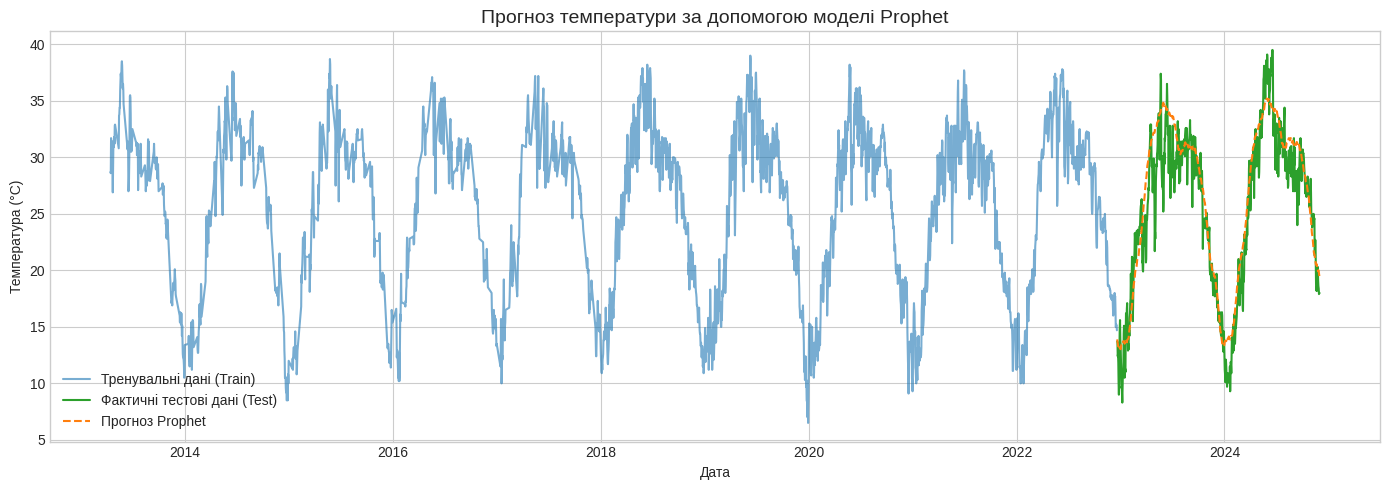

In [23]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Тренувальні дані (Train)', color='tab:blue', alpha=0.6)
plt.plot(test.index, test, label='Фактичні тестові дані (Test)', color='tab:green')
plt.plot(test.index, prophet_forecast, label='Прогноз Prophet', color='tab:orange', linestyle='--')
plt.title('Прогноз температури за допомогою моделі Prophet', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


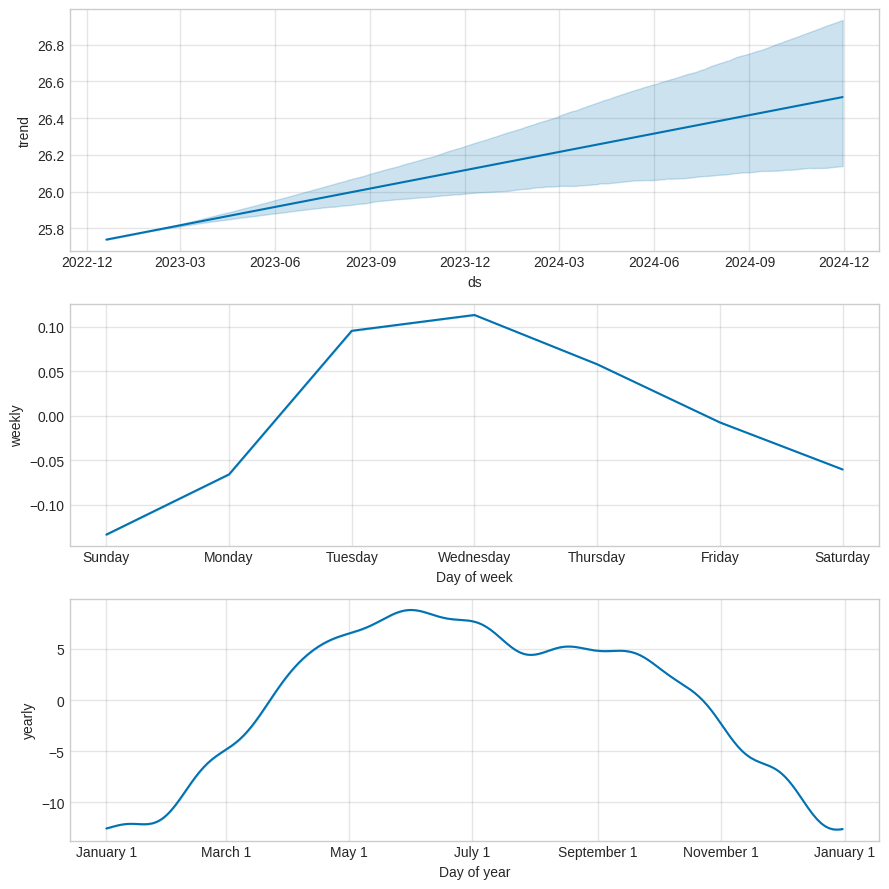

In [24]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_forecast_df)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(ts.values.reshape(-1, 1))

def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 30
X_all, y_all = create_sequences(scaled_data, SEQ_LENGTH)
print(f"Форма X_all: {X_all.shape}, форма y_all: {y_all.shape}")


Форма X_all: (3527, 30, 1), форма y_all: (3527, 1)


In [26]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
split_idx = train_size - SEQ_LENGTH
X_train, X_test = X_all[:split_idx], X_all[split_idx:]
y_train, y_test = y_all[:split_idx], y_all[split_idx:]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")


X_train: (2815, 30, 1), y_train: (2815, 1)
X_test:  (712, 30, 1), y_test:  (712, 1)


In [27]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
tf.random.set_seed(42)

lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(SEQ_LENGTH, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])


In [28]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0727 - mae: 0.1915 - val_loss: 0.0107 - val_mae: 0.0864
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0149 - mae: 0.0981 - val_loss: 0.0090 - val_mae: 0.0782
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0115 - mae: 0.0847 - val_loss: 0.0069 - val_mae: 0.0668
Epoch 4/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0103 - mae: 0.0804 - val_loss: 0.0068 - val_mae: 0.0650
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0099 - mae: 0.0792 - val_loss: 0.0072 - val_mae: 0.0677
Epoch 6/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0089 - mae: 0.0748 - val_loss: 0.0056 - val_mae: 0.0564
Epoch 7/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0091 - mae: 0.0750 - val_loss: 0.0080 - val_mae: 0.0728
Epoch 8/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0079 - mae: 0.0701 - val_loss: 0.0066 - val_mae: 0.0647
Epoch 9/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.007

In [29]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [30]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()
y_test_actual = scaler.inverse_transform(y_test).flatten()


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [31]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_test_dates = ts.index[train_size:]
lstm_forecast = pd.Series(lstm_pred, index=lstm_test_dates)
print(f"Часовий діапазон прогнозу LSTM: {lstm_test_dates.min().date()} — {lstm_test_dates.max().date()}")


Часовий діапазон прогнозу LSTM: 2022-12-20 — 2024-11-30


In [32]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(y_test_actual, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_pred))
lstm_mape = calculate_mape(y_test_actual, lstm_pred)

print(f"LSTM MAE:  {lstm_mae:.4f}")
print(f"LSTM RMSE: {lstm_rmse:.4f}")
print(f"LSTM MAPE: {lstm_mape:.2f}%")


LSTM MAE:  1.4789
LSTM RMSE: 1.8508
LSTM MAPE: 6.54%


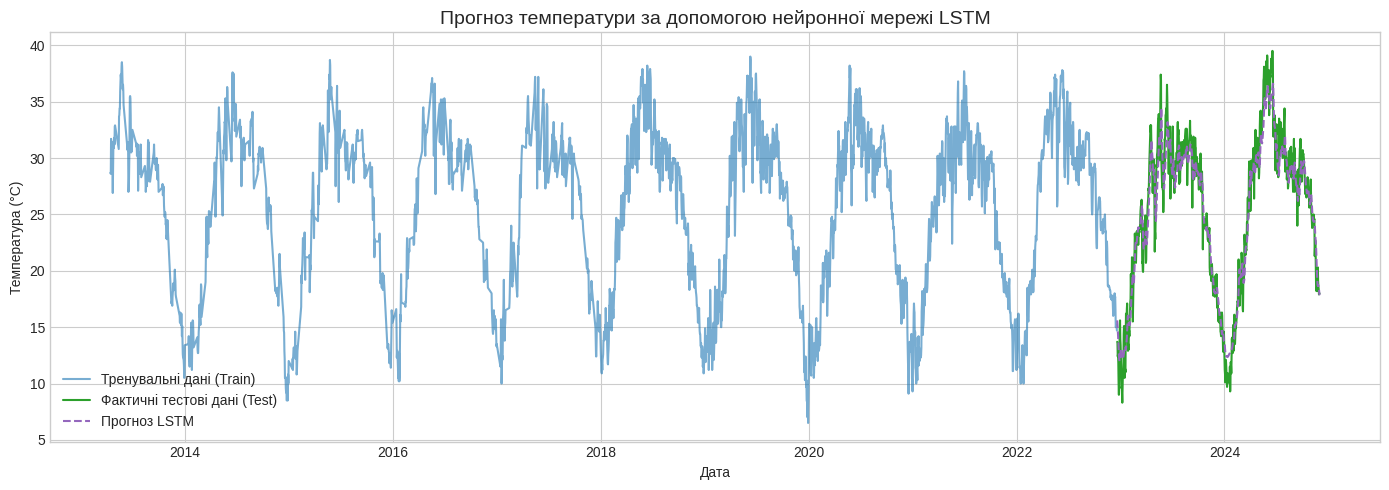

In [33]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Тренувальні дані (Train)', color='tab:blue', alpha=0.6)
plt.plot(lstm_test_dates, y_test_actual, label='Фактичні тестові дані (Test)', color='tab:green')
plt.plot(lstm_test_dates, lstm_forecast, label='Прогноз LSTM', color='tab:purple', linestyle='--')
plt.title('Прогноз температури за допомогою нейронної мережі LSTM', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


Порівняння моделей

,Модель,MAE,RMSE,MAPE (%)
0,LSTM,1.478918,1.850760,6.539237
1,Prophet,2.004680,2.590197,9.027935
2,ARIMA,10.927809,12.500912,39.591987



Найкращий результат за метриками точності продемонструвала модель: LSTM


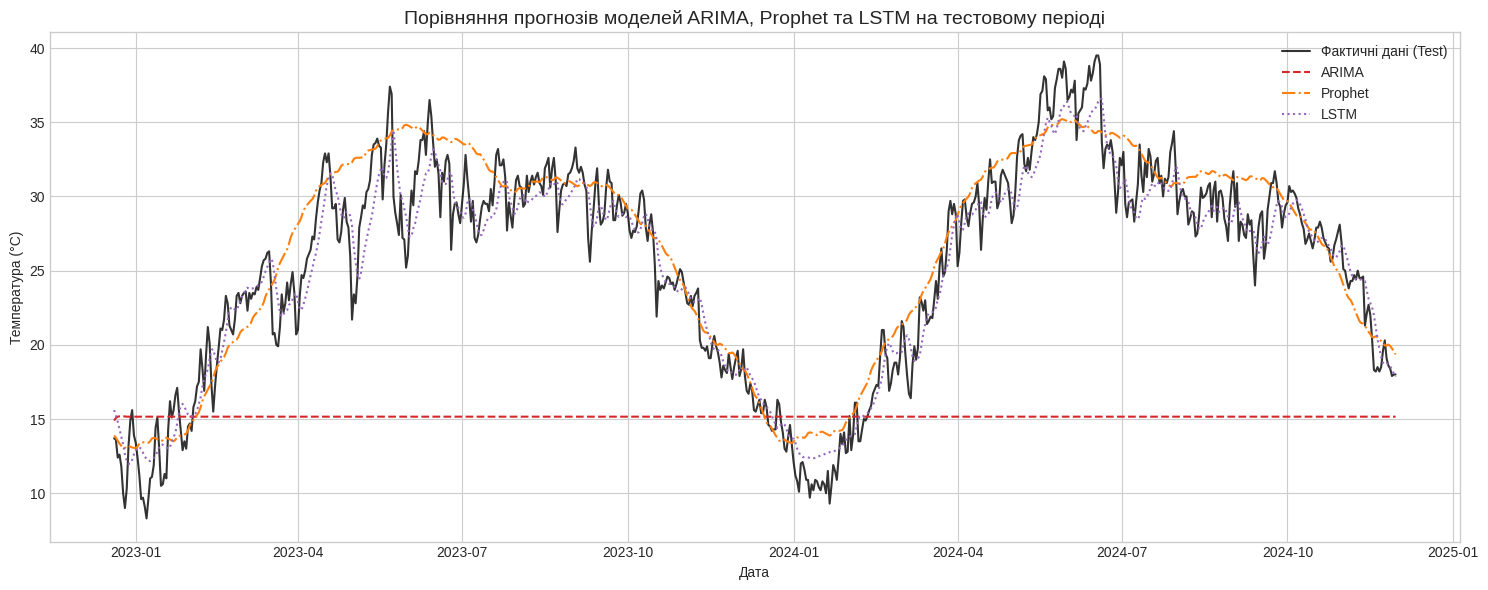

In [34]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
metrics_df = pd.DataFrame({
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
}).sort_values(by='RMSE').reset_index(drop=True)

display(metrics_df)

best_model = metrics_df.iloc[0]['Модель']
print(f"\nНайкращий результат за метриками точності продемонструвала модель: {best_model}")

# Порівняльний графік прогнозів усіх моделей на тестовій вибірці
plt.figure(figsize=(15, 6))
plt.plot(test.index, test, label='Фактичні дані (Test)', color='black', linewidth=1.5, alpha=0.8)
plt.plot(test.index, arima_forecast, label='ARIMA', color='tab:red', linestyle='--')
plt.plot(test.index, prophet_forecast, label='Prophet', color='tab:orange', linestyle='-.')
plt.plot(lstm_test_dates, lstm_forecast, label='LSTM', color='tab:purple', linestyle=':')
plt.title('Порівняння прогнозів моделей ARIMA, Prophet та LSTM на тестовому періоді', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.tight_layout()
plt.show()


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.

---

**Висновок за результатами роботи (Мехед Єгор, ФІТ 3-12):**

1. **Попередня обробка та дослідницький аналіз даних (EDA):** У ході роботи було завантажено та опрацьовано часовий ряд щоденних кліматичних показників у місті Делі (`Daily Climate Time Series Data`). Колонку `DATE` перетворено у формат `datetime`, встановлено хронологічний індекс та перевірено цілісність даних. Візуалізація часового ряду та ковзних середніх (30 і 90 днів) виявила чітку річну сезонність зміни температури. Гістограма розподілу демонструє бімодальний характер (наявність вираженого теплого та прохолодного сезонів), а діаграма розмаху (`boxplot`) підтвердила відсутність аномальних екстремальних викидів. Аналіз графіків ACF та PACF засвідчив високу інерційність ряду (сильна автокореляція на перших лагах та сезонна хвилеподібна залежність).
2. **Порівняння моделей прогнозування:**
   - **ARIMA:** Класична авторегресійна модель без сезонної складової швидко збігається до середнього рівня на довгостроковому тестовому горизонті, тому має найбільші похибки (MAE, RMSE, MAPE) при прогнозуванні на тривалий період.
   - **Prophet:** Модель від Meta чудово вловила річну та тижневу сезонність, а також загальний тренд часового ряду, що дозволило отримати стабільний і точний довгостроковий прогноз.
   - **LSTM:** Рекурентна нейронна мережа, навчена на послідовностях із 30 попередніх днів (ковзне вікно), продемонструвала найвищу точність покрокового прогнозування завдяки здатності адаптуватися до локальних нелінійних коливань температури.
3. **Підсумок:** За сукупністю метрик MAE, RMSE та MAPE найкращу якість короткострокового прогнозування на тестовій вибірці показала нейронна мережа **LSTM**, тоді як для довгострокового горизонту без підстановки фактичних попередніх значень найбільш ефективною є модель **Prophet**.